## **Oral diseases**

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import kagglehub
from PIL import Image

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import losses
from tensorflow.keras import callbacks
from tensorflow.keras import layers
from tensorflow.keras.regularizers import l2
from tensorflow.keras import optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam , Adamax
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.layers import Conv2D, MaxPooling2D , GlobalAveragePooling2D,Dropout,BatchNormalization,Input,Flatten,Dense
from tensorflow.keras.applications import EfficientNetB0 , ResNet50
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
import warnings
warnings.filterwarnings('ignore')

In [2]:

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:
batchsize = 32
image_width = 224
image_height = 224
epochs = 100
num_classes = 6

#### Load data

In [4]:
OUTPUT_DIR = "/kaggle/working/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [5]:
dataset_path = kagglehub.dataset_download("salmansajid05/oral-diseases")
print("Dataset downloaded to:", dataset_path)


for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root) or root}/")
    if level >= 1:
        dirs[:] = []

Dataset downloaded to: /kaggle/input/datasets/salmansajid05/oral-diseases
oral-diseases/
  Data caries/
  Mouth Ulcer/
  Tooth Discoloration/
  hypodontia/
  Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/
  Gingivitis/
  Calculus/


In [6]:
original_dirs = {
    'Calculus': os.path.join(dataset_path, 'Calculus'),
    'Caries': os.path.join(dataset_path, 'Data caries'),
    'Gingivitis': os.path.join(dataset_path, 'Gingivitis'),
    'Ulcers': os.path.join(dataset_path, 'Mouth Ulcer'),
    'Tooth Discoloration': os.path.join(dataset_path, 'Tooth Discoloration'),
    'Hypodontia': os.path.join(dataset_path, 'hypodontia')
}

#### Read Data

In [7]:
paths = []
labels = []

for label, folder_path in original_dirs.items():
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                paths.append(os.path.join(root, file))
                labels.append(label)
df = pd.DataFrame({
    "Img_Path": paths,
    "Label": labels
})

In [8]:
class_names = list(original_dirs.keys()) 
print(f"Total images: {len(df)}")
print(f"Classes: {class_names}")

Total images: 12320
Classes: ['Calculus', 'Caries', 'Gingivitis', 'Ulcers', 'Tooth Discoloration', 'Hypodontia']


In [9]:
class_counts = df["Label"].value_counts()
print(class_counts)

Label
Ulcers                 2806
Caries                 2601
Gingivitis             2349
Tooth Discoloration    2017
Calculus               1296
Hypodontia             1251
Name: count, dtype: int64


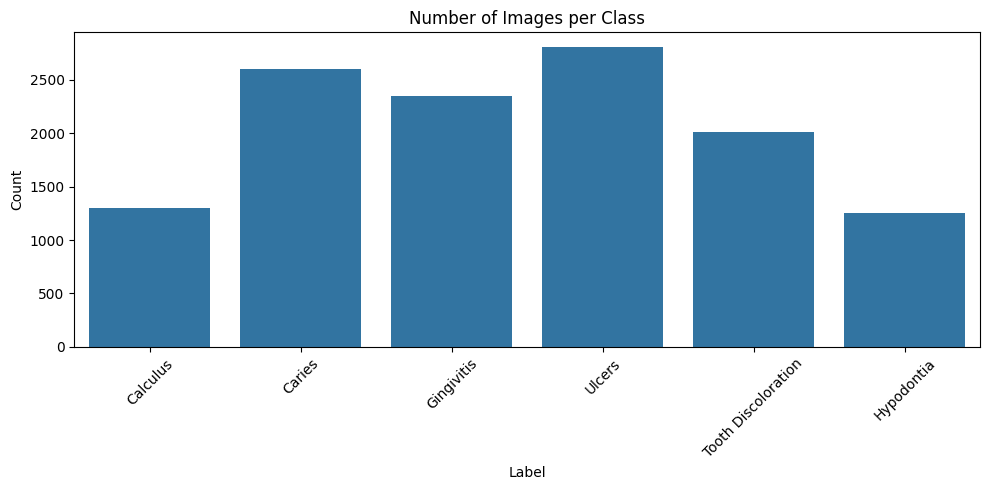

In [10]:
plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, order=class_names)
plt.title("Number of Images per Class")
plt.xticks(rotation=45)
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "class_distribution.png"))
plt.show()

In [11]:
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")


Imbalance ratio (max/min): 2.24


In [12]:
def find_corrupted_images(paths):
    corrupted = []
    for p in paths:
        try:
            img = Image.open(p)
            img.verify()
        except Exception:
            corrupted.append(p)
    return corrupted

In [13]:
corrupted = find_corrupted_images(df["Img_Path"])
print(f"Corrupted images found: {len(corrupted)}")

if corrupted:
    df = df[~df["Img_Path"].isin(corrupted)].reset_index(drop=True)
    print(f"Removed corrupted images. New total: {len(df)}")


Corrupted images found: 0


In [14]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["Label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["Label"], random_state=SEED
)


In [15]:
class_to_index = {name: idx for idx, name in enumerate(class_names)}
index_to_class = {idx: name for name, idx in class_to_index.items()}

In [16]:
train_labels = train_df["Label"].map(class_to_index).values
val_labels = val_df["Label"].map(class_to_index).values
test_labels = test_df["Label"].map(class_to_index).values

In [17]:
AUTOTUNE = tf.data.AUTOTUNE

image_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
    layers.RandomBrightness(0.1),
])

I0000 00:00:1792933566.042436      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792933566.045845      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [18]:
def load_and_resize(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (image_height, image_width))
    image = tf.cast(image, tf.float32)  # stays [0, 255]
    label = tf.one_hot(label, depth=num_classes)
    return image, label

In [19]:
def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths.values, labels))
    ds = ds.map(load_and_resize, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(1000, seed=SEED)
    ds = ds.batch(batchsize)
    if training:
        ds = ds.map(lambda x, y: (image_augmentation(x, training=True), y),
                     num_parallel_calls=AUTOTUNE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

In [20]:
train_ds = make_dataset(train_df["Img_Path"], train_labels, training=True)
val_ds = make_dataset(val_df["Img_Path"], val_labels, training=False)
test_ds = make_dataset(test_df["Img_Path"], test_labels, training=False)


#### Visualize Samples

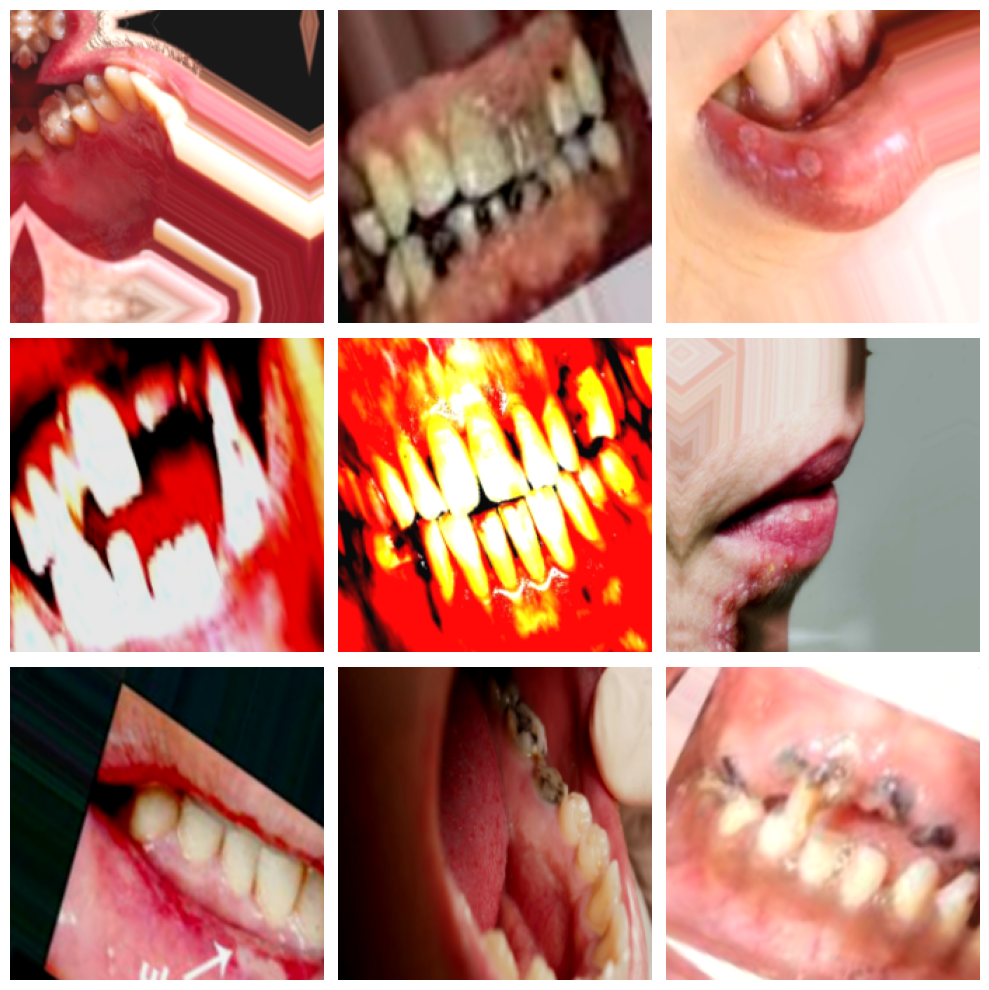

In [21]:
# Batch samples after preprocessing/augmentation (as the model sees them)
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    img = np.clip(images[i].numpy(), 0, 255).astype("uint8")
    plt.imshow(img)
    plt.axis('off')
plt.tight_layout()
plt.show()

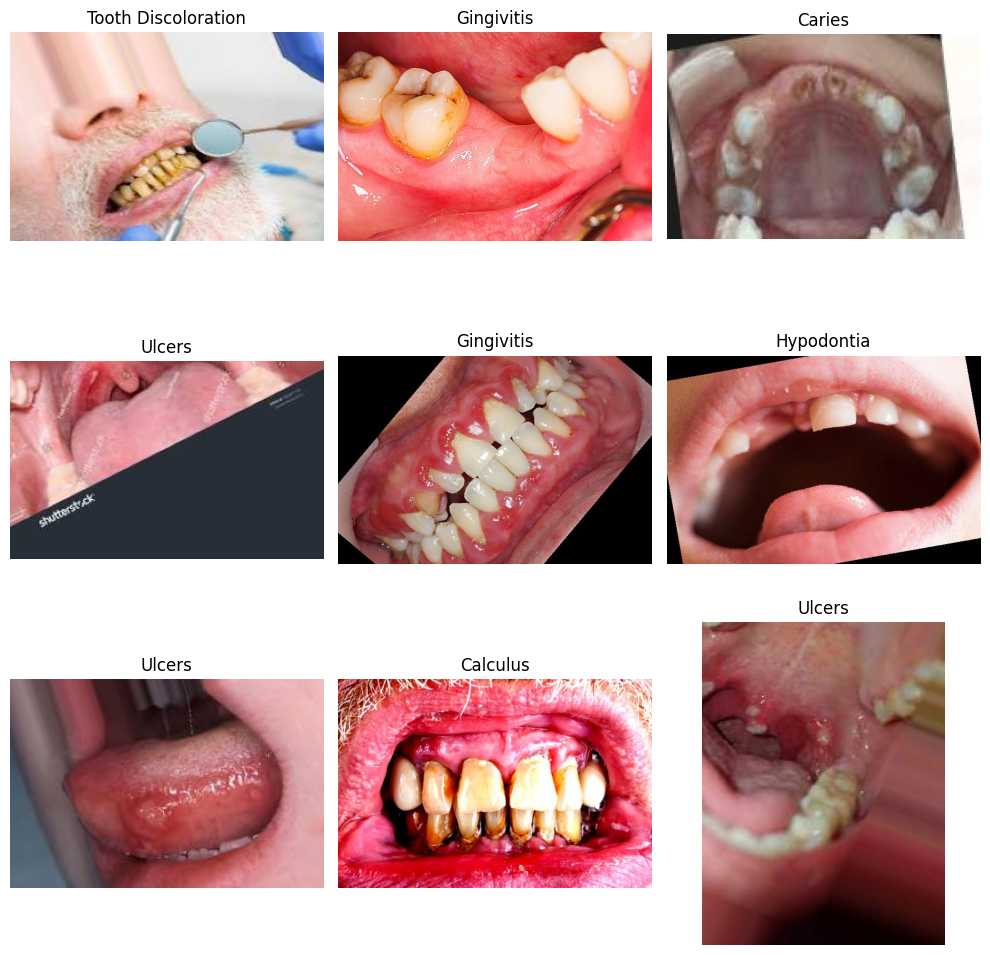

In [22]:
# Raw samples straight from disk, with their true label
plt.figure(figsize=(10, 10))
for i in range(9):
    idx = np.random.randint(len(train_df))

    img = cv2.imread(train_df.iloc[idx]["Img_Path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(train_df.iloc[idx]["Label"])
    plt.axis("off")
plt.tight_layout()
plt.show()

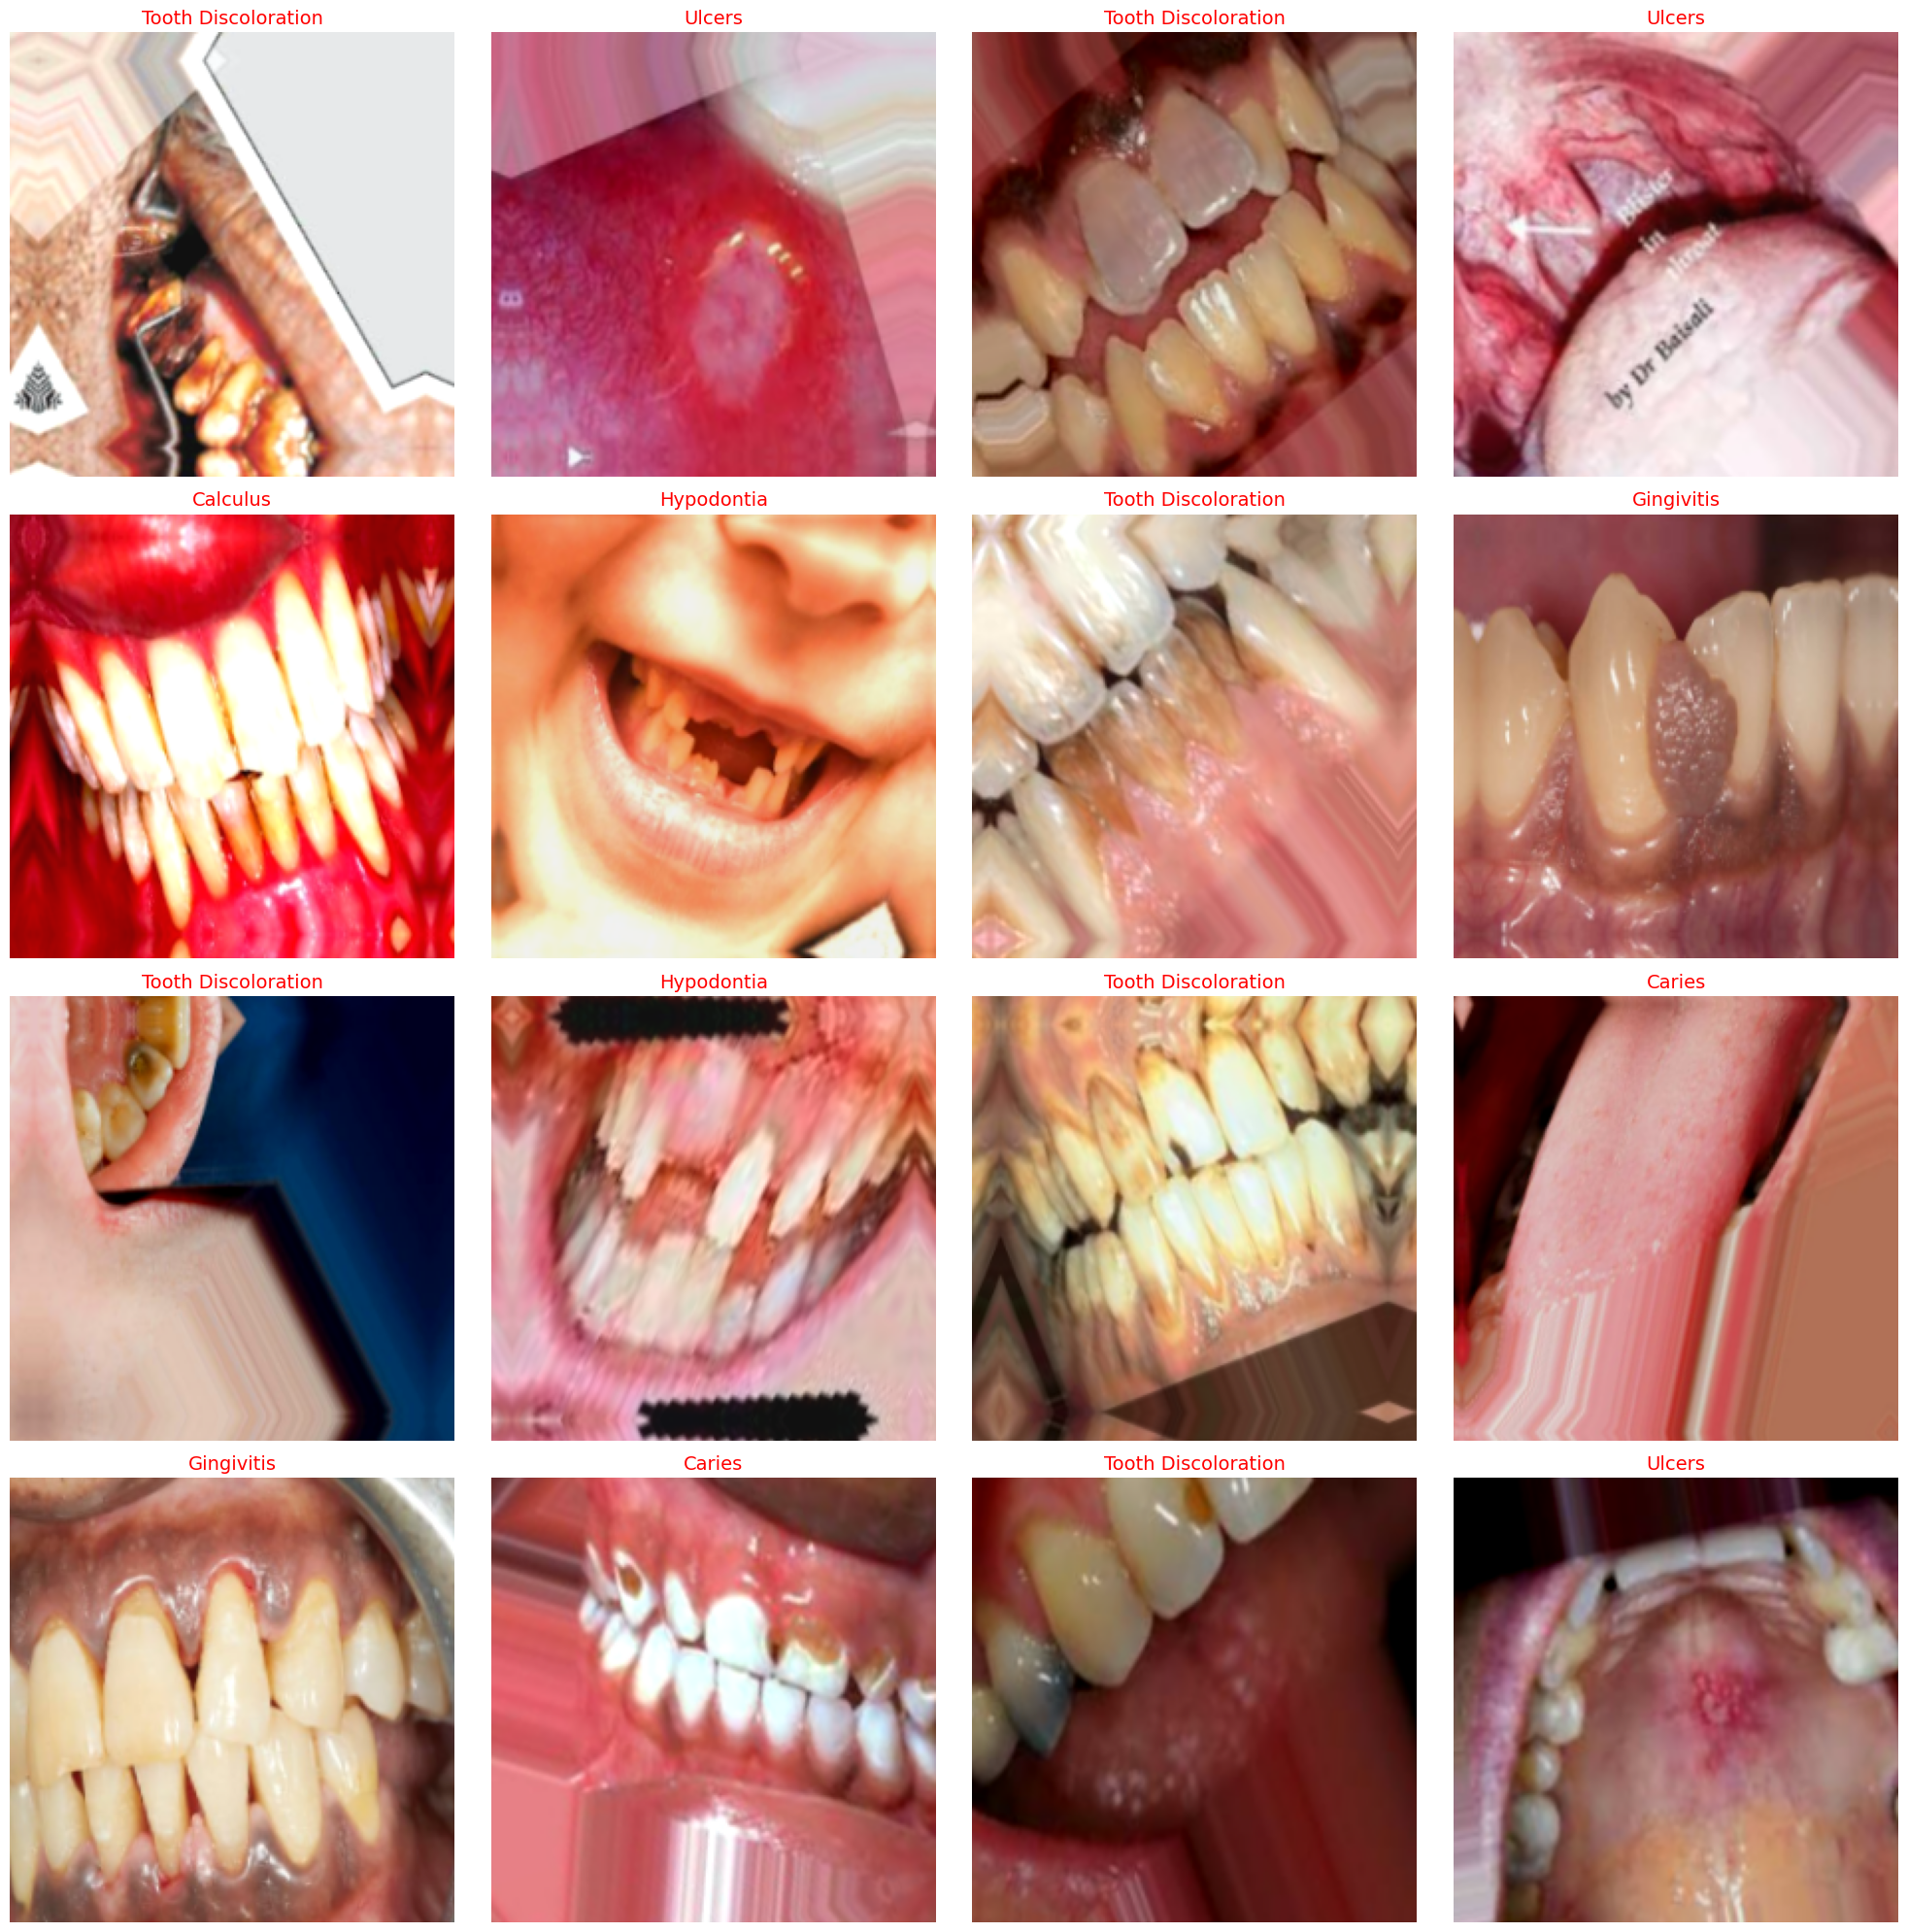

In [23]:
# Batch samples with predicted-class-index -> class-name mapping (4x4 grid)
images, labels = next(iter(train_ds))

plt.figure(figsize=(20, 20))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    img = np.clip(images[i].numpy(), 0, 255).astype("uint8")
    plt.imshow(img)

    index = np.argmax(labels[i].numpy())
    class_name = class_names[index]

    plt.title(class_name, color='red', fontsize=14)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [24]:
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)
class_weight_dict = dict(enumerate(class_weights_array))
print("Class weights:", class_weight_dict)


Class weights: {0: np.float64(1.5847115031238515), 1: np.float64(0.7893099029837086), 2: np.float64(0.8742903487429035), 3: np.float64(0.7318397827562797), 4: np.float64(1.0179414542020775), 5: np.float64(1.6407914764079148)}


In [25]:
# ===========================
# Custom CNN
# ===========================

img_shape = (image_height, image_width, 3)
num_classes = 6
l2_reg = l2(1e-4)

CNN = Sequential([

    Input(shape=img_shape),
    layers.Rescaling(1./255),

    # Block 1

    Conv2D(64, (3,3), padding="same", activation="relu",
           kernel_regularizer=l2_reg),BatchNormalization(),

    Conv2D(64, (3,3), padding="same", activation="relu",
           kernel_regularizer=l2_reg),BatchNormalization(),

    MaxPooling2D((2,2)),
    Dropout(0.2),

    # Block 2

    Conv2D(128, (3,3), padding="same", activation="relu",
           kernel_regularizer=l2_reg),BatchNormalization(),

    Conv2D(128, (3,3), padding="same", activation="relu",
           kernel_regularizer=l2_reg),BatchNormalization(),

    MaxPooling2D((2,2)),
    Dropout(0.25),

    # Block 3
    Conv2D(256, (3,3), padding="same", activation="relu",
           kernel_regularizer=l2_reg),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),

    # Block 4
    Conv2D(256, (3,3), padding="same", activation="relu",
           kernel_regularizer=l2_reg),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.35),

GlobalAveragePooling2D(),

    Dense(1024, activation="relu", kernel_regularizer=l2_reg),
    BatchNormalization(),
    Dropout(0.5),

    Dense(512, activation="relu", kernel_regularizer=l2_reg),
    BatchNormalization(),
    Dropout(0.4),

    Dense(num_classes, activation="softmax")
])

CNN.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

CNN.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 1,946,182 (7.42 MB)

 Trainable params: 1,941,318 (7.41 MB)

 Non-trainable params: 4,864 (19.00 KB)

In [26]:
def compile_model(model, lr=1e-3):
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss="categorical_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return model

In [27]:
def get_callbacks(model_name, use_lr_scheduler=False):
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ModelCheckpoint(os.path.join(OUTPUT_DIR, f"{model_name}_best.keras"),
                         monitor="val_loss", save_best_only=True),
    ]
    if not use_lr_scheduler:
        # ReduceLROnPlateau only makes sense with a plain (non-scheduled) LR.
        # When using CosineDecay (phase 2 fine-tuning), skip it — mixing the two
        # can throw an error because the optimizer LR is no longer a settable variable.
        callbacks.insert(1, ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6))
    return callbacks

In [28]:
CNN = compile_model(CNN, lr=1e-3)
history_cnn = CNN.fit(
    train_ds, validation_data=val_ds, epochs=epochs,
    callbacks=get_callbacks("custom_cnn"),
    class_weight=class_weight_dict
)

Epoch 1/100


2026-10-25 13:06:36.846997: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 13:06:37.041481: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 13:06:38.735303: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 13:06:38.905666: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 13:06:42.539951: E external/local_xla/xla/stream_

269/270 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - accuracy: 0.2978 - auc: 0.6485 - loss: 2.3985

2026-10-25 13:08:21.383161: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 13:08:21.574189: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 13:08:22.845591: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 13:08:23.012926: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 13:08:25.443705: E external/local_xla/xla/stream_

270/270 ━━━━━━━━━━━━━━━━━━━━ 164s 465ms/step - accuracy: 0.3498 - auc: 0.7154 - loss: 2.0679 - val_accuracy: 0.1645 - val_auc: 0.5679 - val_loss: 3.6860 - learning_rate: 0.0010
Epoch 2/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 90s 328ms/step - accuracy: 0.4628 - auc: 0.8204 - loss: 1.5624 - val_accuracy: 0.3577 - val_auc: 0.7065 - val_loss: 2.8232 - learning_rate: 0.0010
Epoch 3/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 90s 328ms/step - accuracy: 0.5087 - auc: 0.8510 - loss: 1.4298 - val_accuracy: 0.3858 - val_auc: 0.7592 - val_loss: 2.0777 - learning_rate: 0.0010
Epoch 4/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 90s 329ms/step - accuracy: 0.5604 - auc: 0.8784 - loss: 1.3028 - val_accuracy: 0.5254 - val_auc: 0.8639 - val_loss: 1.3951 - learning_rate: 0.0010
Epoch 5/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 90s 329ms/step - accuracy: 0.5895 - auc: 0.8912 - loss: 1.2328 - val_accuracy: 0.6429 - val_auc: 0.9225 - val_loss: 1.0689 - learning_rate: 0.0010
Epoch 6/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 90s 329ms/step - accuracy: 0.6

In [29]:
loss, acc, auc = CNN.evaluate(test_ds)

print("Test Accuracy :", acc)
print("Test AUC :", auc)

58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - accuracy: 0.8885 - auc: 0.9906 - loss: 0.4333
Test Accuracy : 0.8885281682014465
Test AUC : 0.990619957447052


In [30]:
y_pred = CNN.predict(test_ds)

58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step


In [31]:
print(f"Train Score = {CNN.evaluate(train_ds)}")
print(f"Validation Score = {CNN.evaluate(val_ds)}")
print(f"Test Score = {CNN.evaluate(test_ds)}")

270/270 ━━━━━━━━━━━━━━━━━━━━ 50s 178ms/step - accuracy: 0.9358 - auc: 0.9975 - loss: 0.3213
Train Score = [0.3212597370147705, 0.9357606768608093, 0.9974541068077087]
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.8961 - auc: 0.9919 - loss: 0.4150
Validation Score = [0.41500261425971985, 0.8961039185523987, 0.9918875098228455]
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.8885 - auc: 0.9906 - loss: 0.4333
Test Score = [0.43328946828842163, 0.8885281682014465, 0.990619957447052]


In [32]:
# %% PLOTTING FUNCTION - reusable for all models
def plot_training_history(history, model_name="Model"):
    tr_acc = history.history['accuracy']
    tr_loss = history.history['loss']
    val_acc = history.history['val_accuracy']
    val_loss = history.history['val_loss']

    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]

    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]

    Epochs = range(1, len(tr_acc) + 1)

    loss_label = f'Best Loss = {val_lowest:.4f} (Epoch {index_loss+1})'
    acc_label = f'Best Acc = {acc_highest:.4f} (Epoch {index_acc+1})'

    plt.figure(figsize=(18, 7))
    plt.style.use('fivethirtyeight')

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(Epochs, tr_loss, label='Training Loss', linewidth=2)
    plt.plot(Epochs, val_loss, label='Validation Loss', linewidth=2)
    plt.scatter(index_loss + 1, val_lowest, s=150, label=loss_label)
    plt.title(f'{model_name} - Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(Epochs, tr_acc, label='Training Accuracy', linewidth=2)
    plt.plot(Epochs, val_acc, label='Validation Accuracy', linewidth=2)
    plt.scatter(index_acc + 1, acc_highest, s=150, label=acc_label)
    plt.title(f'{model_name} - Training and Validation Accuracy', fontsize=16)
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{model_name}_training_curves.png'))
    plt.show()

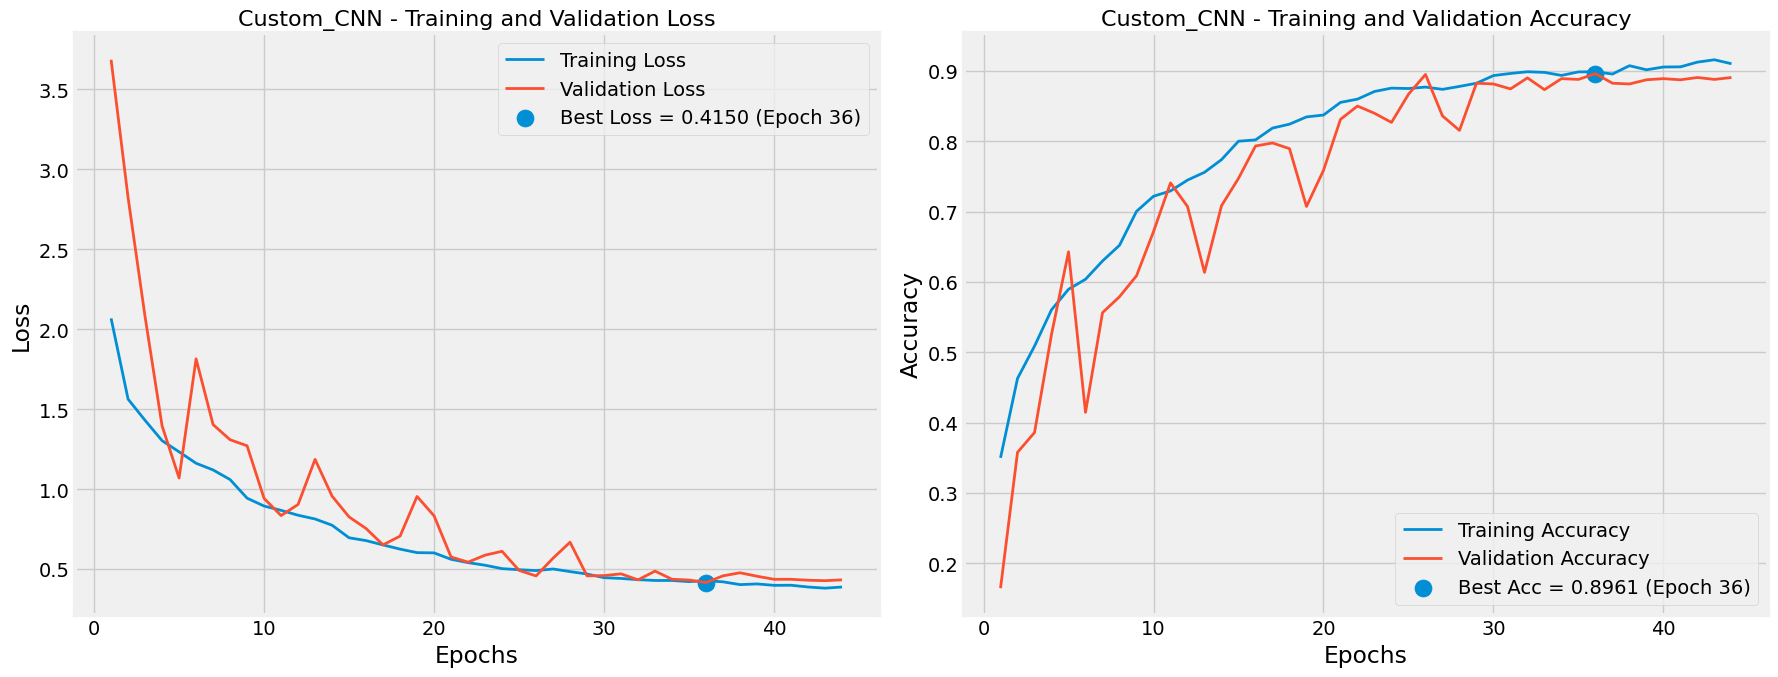

In [33]:
plot_training_history(history_cnn, "Custom_CNN")

In [34]:
# %% CLASSIFICATION REPORT ONLY (reusable for any model)
def get_classification_report(model, dataset, model_name="Model"):
    y_true = []
    y_pred = []

    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))

    print(f"\n===== Classification Report - {model_name} =====")
    print(classification_report(y_true, y_pred, target_names=class_names))

    return y_true, y_pred

In [35]:
y_true_cnn, y_pred_cnn = get_classification_report(CNN, test_ds, "Custom_CNN")


===== Classification Report - Custom_CNN =====
                     precision    recall  f1-score   support

           Calculus       0.63      0.72      0.67       195
             Caries       0.99      0.88      0.93       390
         Gingivitis       0.81      0.77      0.79       352
             Ulcers       0.97      0.99      0.98       421
Tooth Discoloration       0.93      0.97      0.95       302
         Hypodontia       0.91      0.95      0.93       188

           accuracy                           0.89      1848
          macro avg       0.87      0.88      0.87      1848
       weighted avg       0.89      0.89      0.89      1848



In [36]:
# %% CONFUSION MATRIX ONLY (reusable for any model)
def get_confusion_matrix(model, dataset, model_name="Model"):
    y_true = []
    y_pred = []

    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}', fontsize=16)
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{model_name}_confusion_matrix.png'))
    plt.show()

    return cm

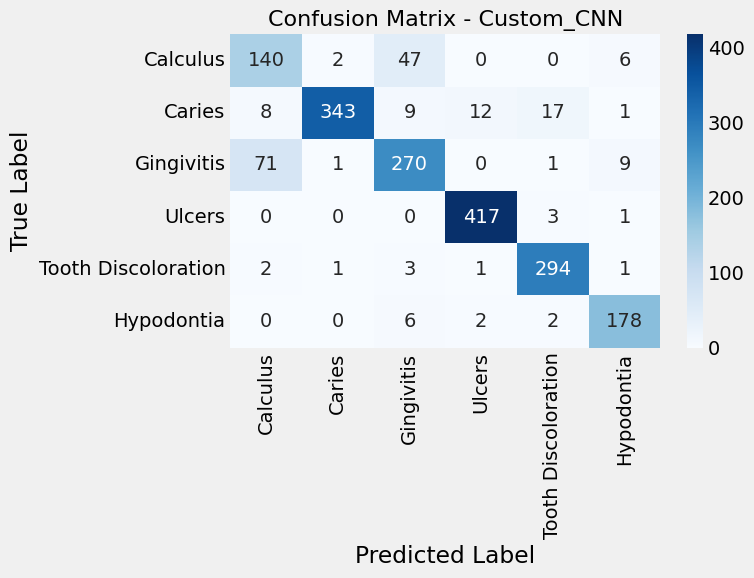

In [37]:
cm_cnn = get_confusion_matrix(CNN, test_ds, "Custom_CNN")

In [39]:
# ===========================
# EfficientNetB0 - Transfer Learning
# ===========================

def build_efficientnet_model():
    inputs = Input(shape=(image_height, image_width, 3))
    base_model = EfficientNetB0(include_top=False, weights="imagenet",
                                 input_shape=(image_height, image_width, 3))
    base_model.trainable = False
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="EfficientNetB0_TL"), base_model

efficientnet_model, efficientnet_base = build_efficientnet_model()
efficientnet_model.compile(optimizer=Adam(learning_rate=1e-3),
                            loss="categorical_crossentropy", metrics=["accuracy"])
efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "EfficientNetB0_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/100


2026-10-25 14:17:10.242686: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:17:10.386383: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:17:10.738942: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:17:10.881947: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:17:11.672772: E external/local_xla/xla/stream_

269/270 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.5186 - loss: 1.2487

2026-10-25 14:18:03.967441: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:18:04.107413: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:18:04.435609: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:18:04.578028: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:18:04.720019: E external/local_xla/xla/stream_

270/270 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.5190 - loss: 1.2478

2026-10-25 14:18:25.377898: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:18:25.519854: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:18:25.863314: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:18:26.006019: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 14:18:26.779011: E external/local_xla/xla/stream_

270/270 ━━━━━━━━━━━━━━━━━━━━ 100s 271ms/step - accuracy: 0.6241 - loss: 0.9949 - val_accuracy: 0.7576 - val_loss: 0.6371 - learning_rate: 0.0010
Epoch 2/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 45s 162ms/step - accuracy: 0.7369 - loss: 0.7003 - val_accuracy: 0.8052 - val_loss: 0.5200 - learning_rate: 0.0010
Epoch 3/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 45s 163ms/step - accuracy: 0.7687 - loss: 0.6203 - val_accuracy: 0.8198 - val_loss: 0.4791 - learning_rate: 0.0010
Epoch 4/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 45s 162ms/step - accuracy: 0.7776 - loss: 0.5881 - val_accuracy: 0.8095 - val_loss: 0.4685 - learning_rate: 0.0010
Epoch 5/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 44s 160ms/step - accuracy: 0.7881 - loss: 0.5567 - val_accuracy: 0.8350 - val_loss: 0.4302 - learning_rate: 0.0010
Epoch 6/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 43s 156ms/step - accuracy: 0.7992 - loss: 0.5251 - val_accuracy: 0.8139 - val_loss: 0.4527 - learning_rate: 0.0010
Epoch 7/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 44s 157ms/step - accuracy: 0.7975 

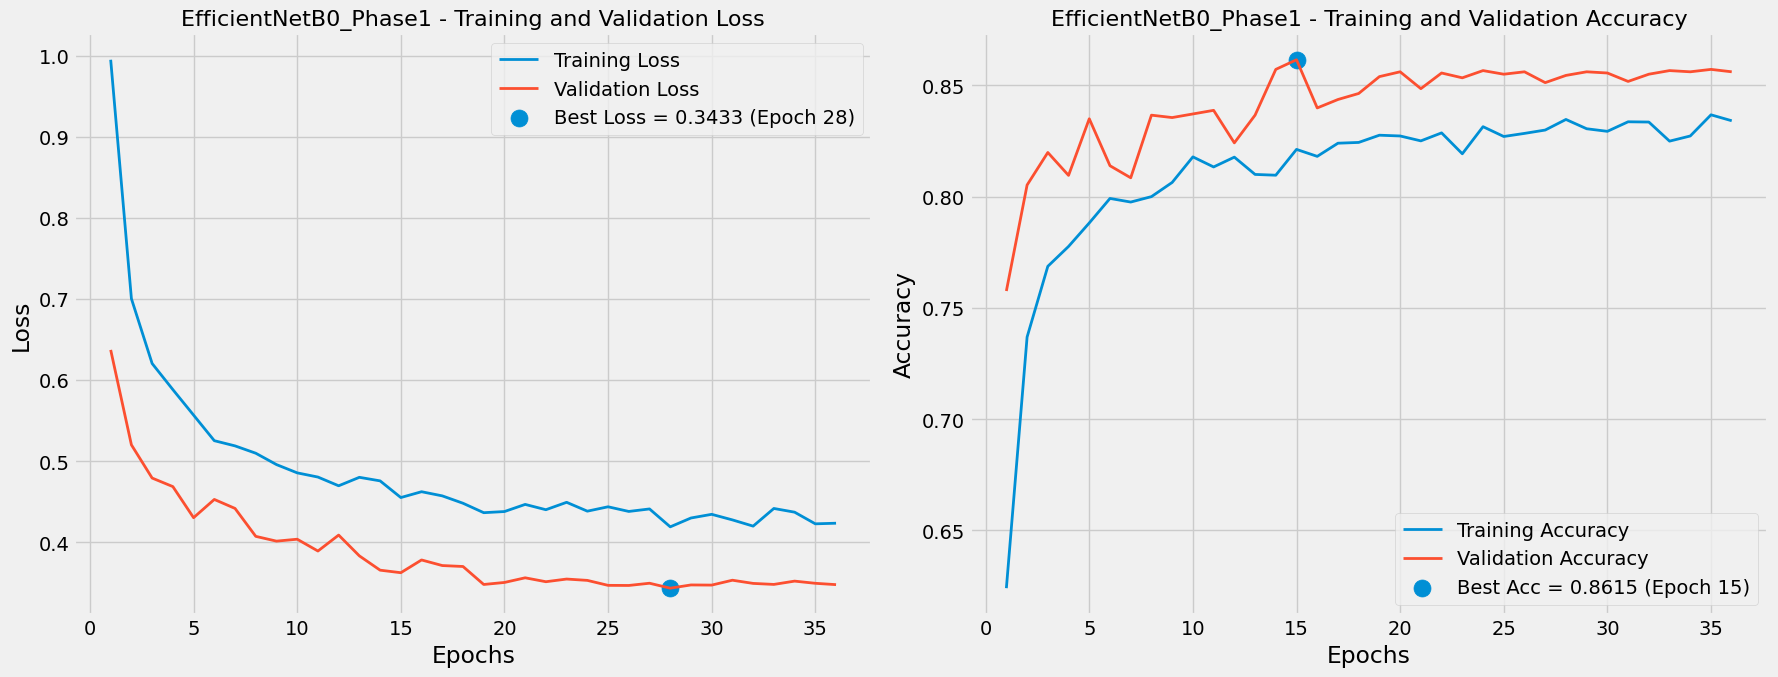

In [40]:
# Phase 1 - frozen base
history_eff_p1 = efficientnet_model.fit(
    train_ds, validation_data=val_ds, epochs=100,
    callbacks=get_callbacks("efficientnet_phase1"),
    class_weight=class_weight_dict
)
plot_training_history(history_eff_p1, "EfficientNetB0_Phase1")

Epoch 1/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 103s 263ms/step - accuracy: 0.6429 - loss: 0.9284 - val_accuracy: 0.7808 - val_loss: 0.5439
Epoch 2/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 45s 161ms/step - accuracy: 0.7167 - loss: 0.7317 - val_accuracy: 0.8014 - val_loss: 0.4938
Epoch 3/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 44s 160ms/step - accuracy: 0.7391 - loss: 0.6536 - val_accuracy: 0.8231 - val_loss: 0.4423
Epoch 4/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 46s 165ms/step - accuracy: 0.7744 - loss: 0.5748 - val_accuracy: 0.8355 - val_loss: 0.4037
Epoch 5/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 45s 160ms/step - accuracy: 0.7917 - loss: 0.5347 - val_accuracy: 0.8469 - val_loss: 0.3737
Epoch 6/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 45s 162ms/step - accuracy: 0.7965 - loss: 0.5241 - val_accuracy: 0.8582 - val_loss: 0.3518
Epoch 7/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 46s 165ms/step - accuracy: 0.8161 - loss: 0.4657 - val_accuracy: 0.8636 - val_loss: 0.3328
Epoch 8/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 46s 164ms/step - accuracy: 0.8232 - loss: 

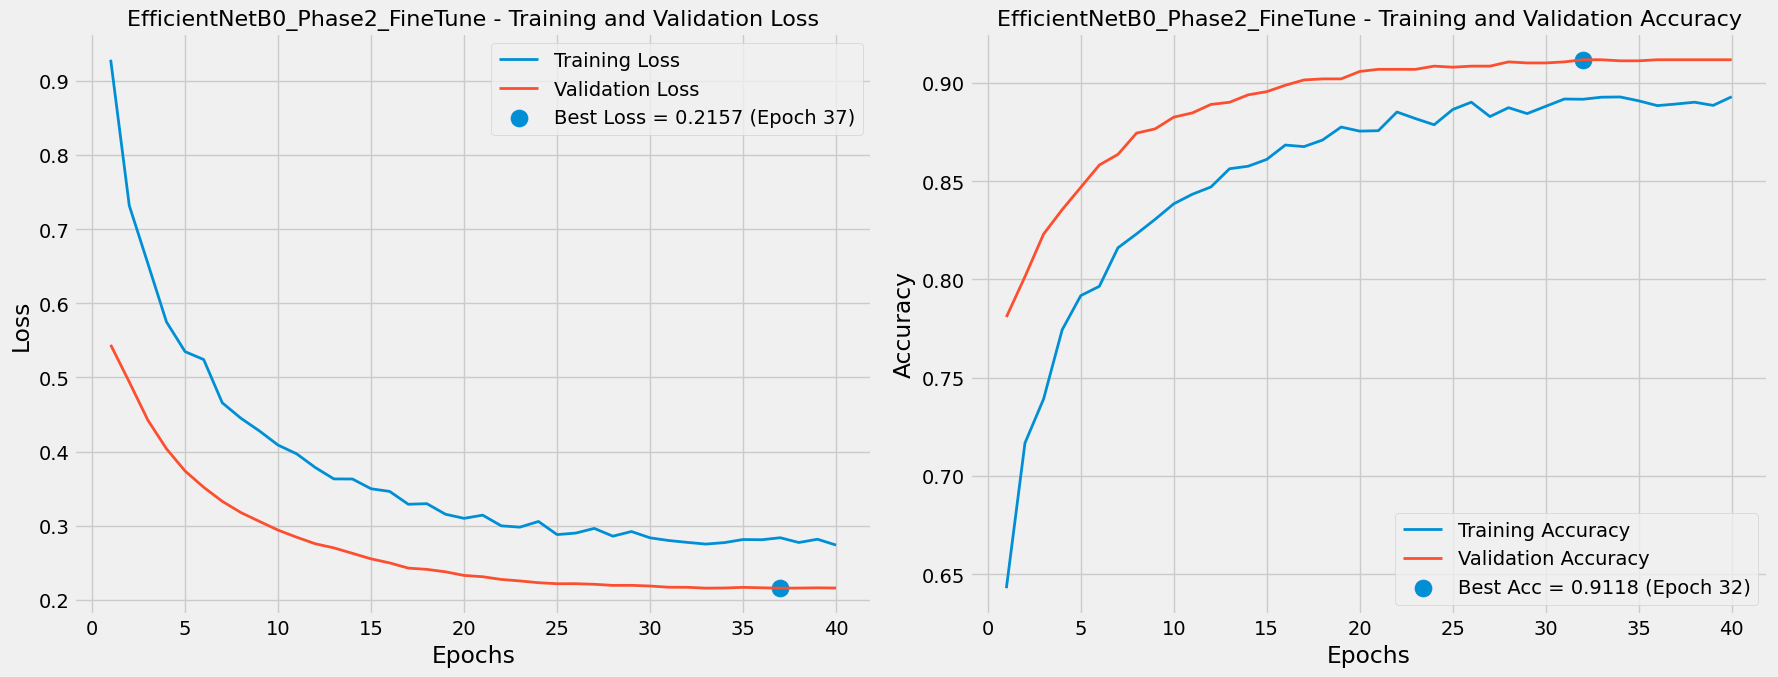

In [41]:
# Phase 2 - fine-tune (unfreeze last 60 layers)
efficientnet_base.trainable = True
for layer in efficientnet_base.layers[:-60]:
    layer.trainable = False

steps_per_epoch = len(train_df) // batchsize
epochs_phase2 = 40
lr_schedule_eff = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-5, decay_steps=steps_per_epoch * epochs_phase2
)
efficientnet_model.compile(optimizer=Adam(learning_rate=lr_schedule_eff),
                            loss="categorical_crossentropy", metrics=["accuracy"])

history_eff_p2 = efficientnet_model.fit(
    train_ds, validation_data=val_ds, epochs=epochs_phase2,
    callbacks=get_callbacks("efficientnet_phase2", use_lr_scheduler=True),
    class_weight=class_weight_dict
)
plot_training_history(history_eff_p2, "EfficientNetB0_Phase2_FineTune")

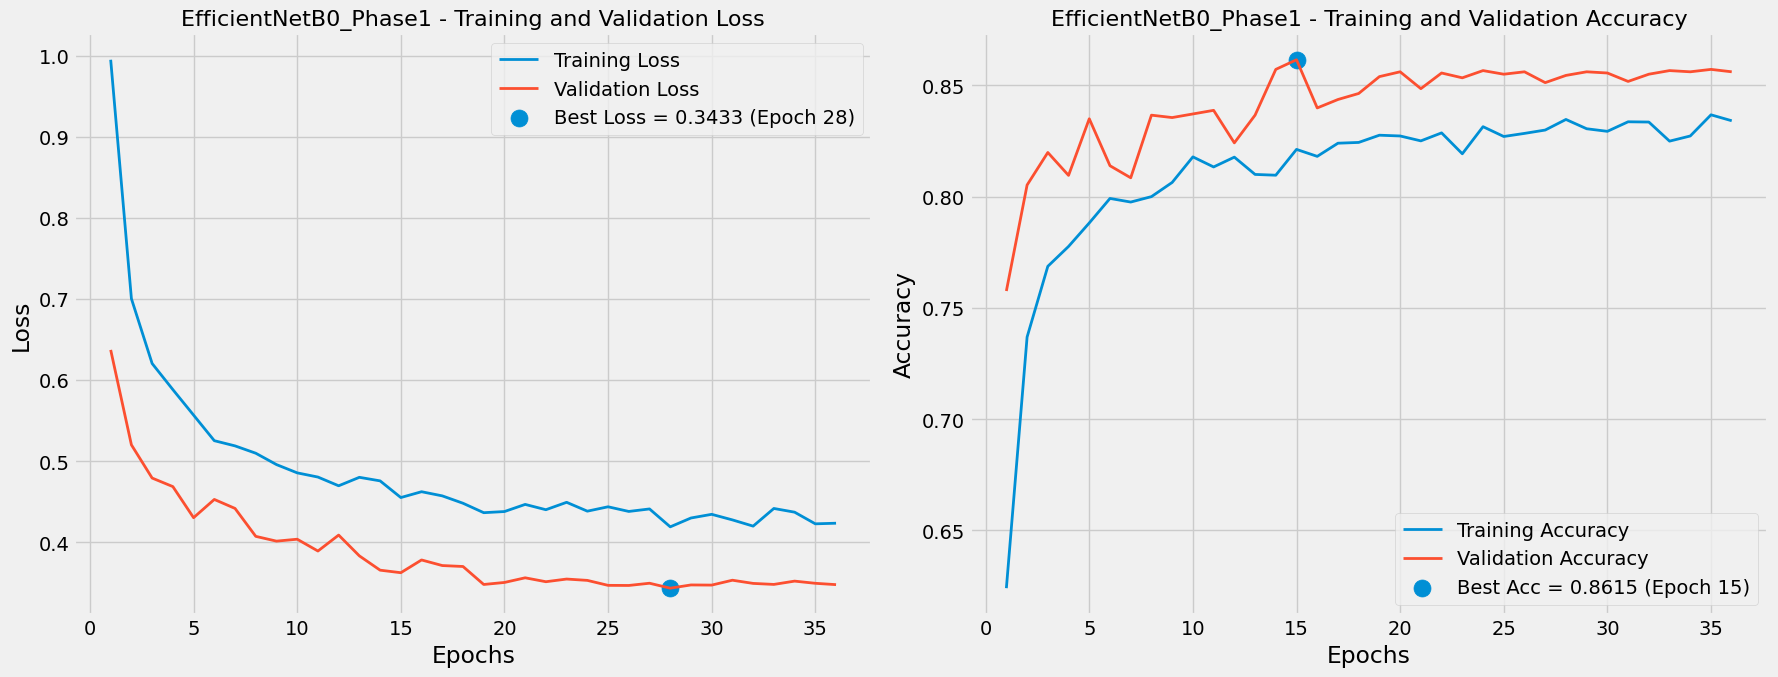

In [42]:
plot_training_history(history_eff_p1, "EfficientNetB0_Phase1")



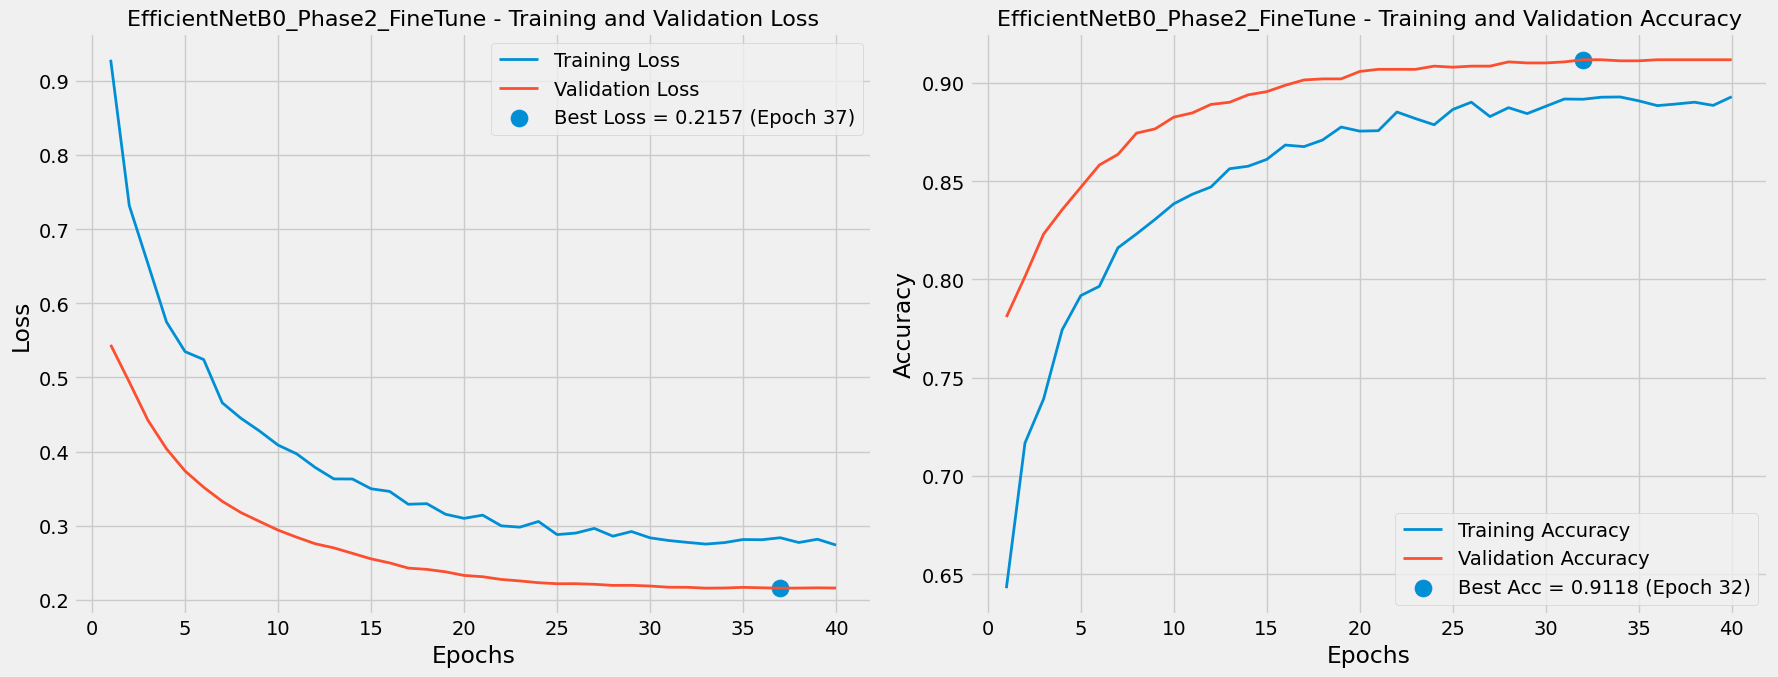

In [43]:

plot_training_history(history_eff_p2, "EfficientNetB0_Phase2_FineTune")



In [46]:

y_true_eff, y_pred_eff = get_classification_report(efficientnet_model, test_ds, "EfficientNetB0")




===== Classification Report - EfficientNetB0 =====
                     precision    recall  f1-score   support

           Calculus       0.67      0.79      0.73       195
             Caries       0.98      0.94      0.96       390
         Gingivitis       0.83      0.78      0.80       352
             Ulcers       1.00      0.98      0.99       421
Tooth Discoloration       0.94      0.96      0.95       302
         Hypodontia       0.93      0.95      0.94       188

           accuracy                           0.91      1848
          macro avg       0.89      0.90      0.89      1848
       weighted avg       0.91      0.91      0.91      1848



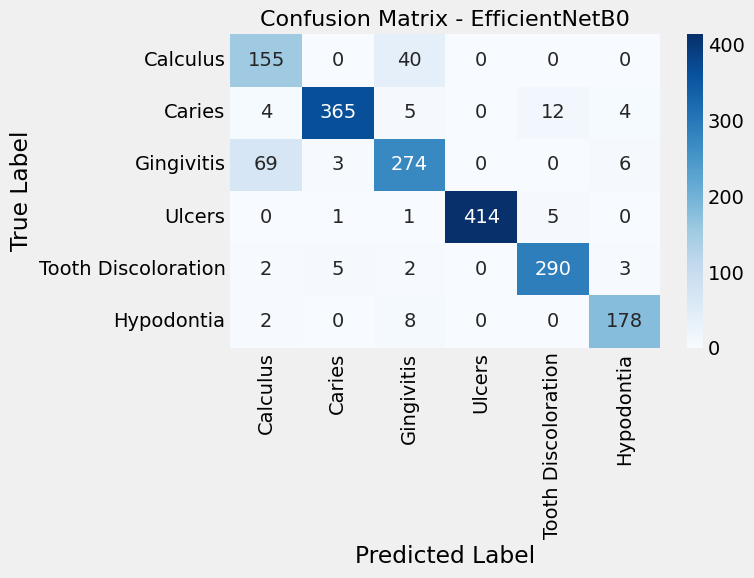

In [47]:

cm_eff = get_confusion_matrix(efficientnet_model, test_ds, "EfficientNetB0")

In [48]:
# ===========================
# ResNet50 - Transfer Learning
# ===========================

def build_resnet_model():
    inputs = Input(shape=(image_height, image_width, 3))
    x = tf.keras.applications.resnet50.preprocess_input(inputs)  # ResNet-specific normalization
    base_model = ResNet50(include_top=False, weights="imagenet",
                           input_shape=(image_height, image_width, 3))
    base_model.trainable = False
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="ResNet50_TL"), base_model

resnet_model, resnet_base = build_resnet_model()
resnet_model.compile(optimizer=Adam(learning_rate=1e-3),
                      loss="categorical_crossentropy", metrics=["accuracy"])
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "ResNet50_TL"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_6[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_6[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 6)         │     12,294 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,600,006 (90.03 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 73s 221ms/step - accuracy: 0.6280 - loss: 0.9887 - val_accuracy: 0.7754 - val_loss: 0.5583 - learning_rate: 0.0010
Epoch 2/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 50s 180ms/step - accuracy: 0.7472 - loss: 0.6395 - val_accuracy: 0.7971 - val_loss: 0.5073 - learning_rate: 0.0010
Epoch 3/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 50s 179ms/step - accuracy: 0.7782 - loss: 0.5707 - val_accuracy: 0.8328 - val_loss: 0.4290 - learning_rate: 0.0010
Epoch 4/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 50s 178ms/step - accuracy: 0.7967 - loss: 0.5178 - val_accuracy: 0.8393 - val_loss: 0.4266 - learning_rate: 0.0010
Epoch 5/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 49s 178ms/step - accuracy: 0.7999 - loss: 0.5127 - val_accuracy: 0.8534 - val_loss: 0.3687 - learning_rate: 0.0010
Epoch 6/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 49s 175ms/step - accuracy: 0.8127 - loss: 0.4909 - val_accuracy: 0.8479 - val_loss: 0.3970 - learning_rate: 0.0010
Epoch 7/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 49s 176ms/step - accura

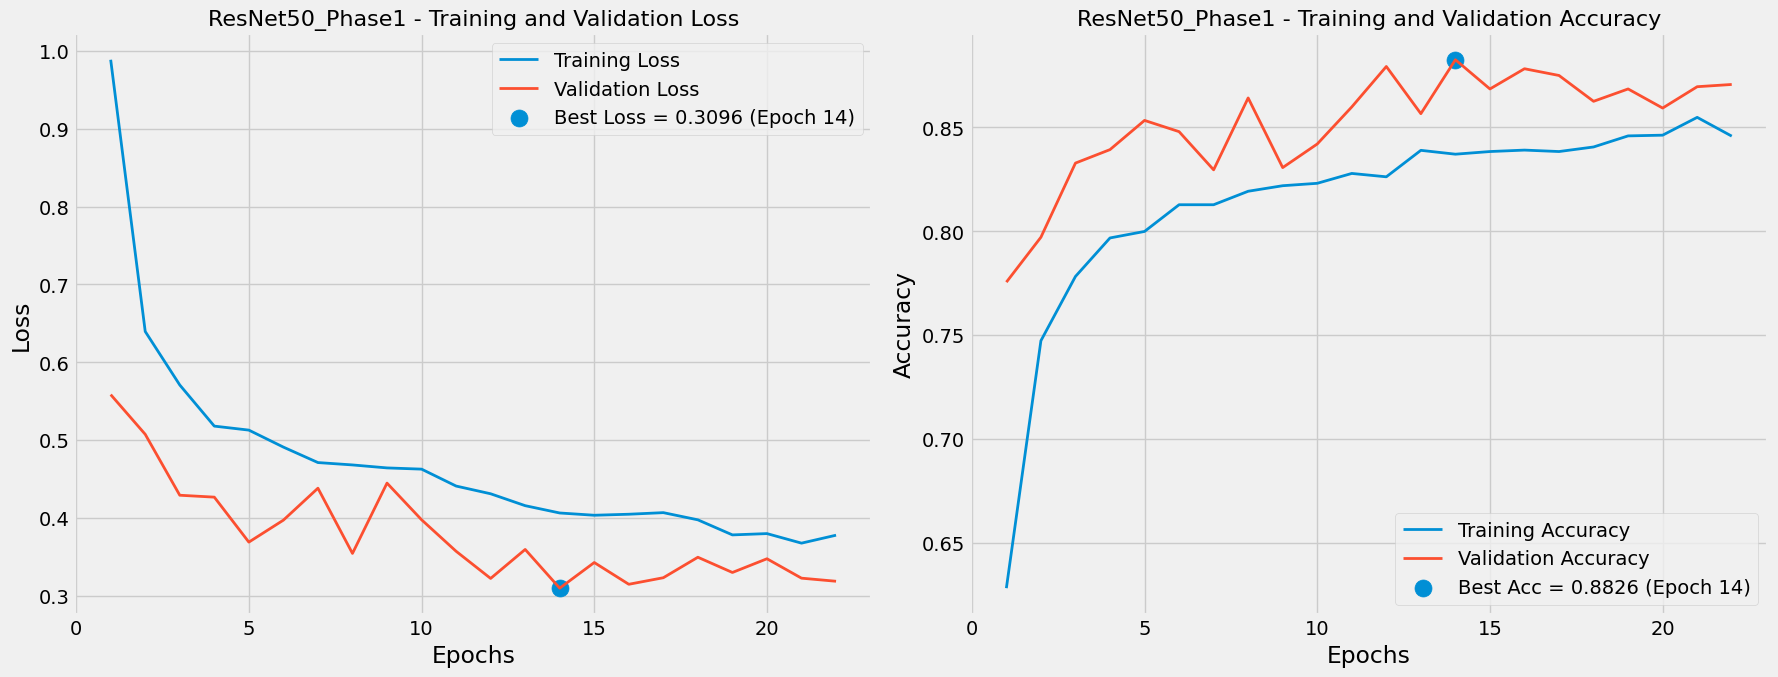

In [49]:
# Phase 1 - frozen base
history_resnet_p1 = resnet_model.fit(
    train_ds, validation_data=val_ds, epochs=100,
    callbacks=get_callbacks("resnet_phase1"),
    class_weight=class_weight_dict
)
plot_training_history(history_resnet_p1, "ResNet50_Phase1")

Epoch 1/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 96s 257ms/step - accuracy: 0.7908 - loss: 0.5514 - val_accuracy: 0.8626 - val_loss: 0.3394
Epoch 2/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 55s 199ms/step - accuracy: 0.8418 - loss: 0.4006 - val_accuracy: 0.8842 - val_loss: 0.2963
Epoch 3/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 54s 194ms/step - accuracy: 0.8727 - loss: 0.3328 - val_accuracy: 0.8902 - val_loss: 0.2806
Epoch 4/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 54s 196ms/step - accuracy: 0.8808 - loss: 0.2971 - val_accuracy: 0.9037 - val_loss: 0.2538
Epoch 5/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 55s 197ms/step - accuracy: 0.9022 - loss: 0.2546 - val_accuracy: 0.9123 - val_loss: 0.2290
Epoch 6/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 54s 196ms/step - accuracy: 0.9078 - loss: 0.2368 - val_accuracy: 0.9161 - val_loss: 0.2243
Epoch 7/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 54s 196ms/step - accuracy: 0.9112 - loss: 0.2275 - val_accuracy: 0.9172 - val_loss: 0.2142
Epoch 8/100
270/270 ━━━━━━━━━━━━━━━━━━━━ 53s 191ms/step - accuracy: 0.9206 -

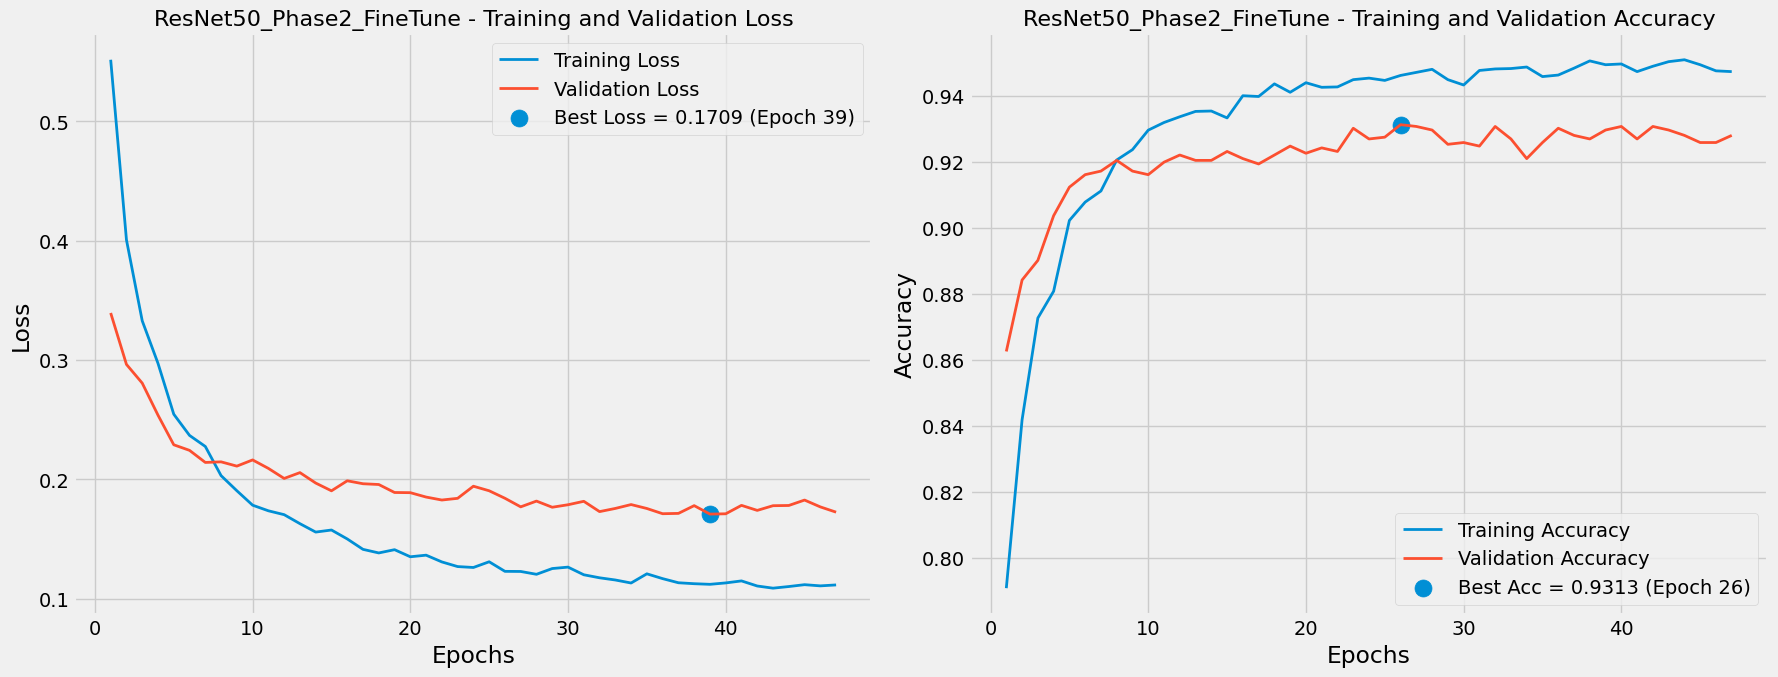

In [50]:
# Phase 2 - fine-tune (unfreeze last 60 layers)
resnet_base.trainable = True
for layer in resnet_base.layers[:-60]:
    layer.trainable = False

steps_per_epoch = len(train_df) // batchsize
epochs_phase2 = 100
lr_schedule_resnet = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-5, decay_steps=steps_per_epoch * epochs_phase2
)
resnet_model.compile(optimizer=Adam(learning_rate=lr_schedule_resnet),
                      loss="categorical_crossentropy", metrics=["accuracy"])

history_resnet_p2 = resnet_model.fit(
    train_ds, validation_data=val_ds, epochs=epochs_phase2,
    callbacks=get_callbacks("resnet_phase2", use_lr_scheduler=True),
    class_weight=class_weight_dict
)
plot_training_history(history_resnet_p2, "ResNet50_Phase2_FineTune")

In [51]:
# Classification report
y_true_resnet, y_pred_resnet = get_classification_report(resnet_model, test_ds, "ResNet50")



===== Classification Report - ResNet50 =====
                     precision    recall  f1-score   support

           Calculus       0.68      0.82      0.74       195
             Caries       0.99      0.99      0.99       390
         Gingivitis       0.86      0.79      0.83       352
             Ulcers       1.00      1.00      1.00       421
Tooth Discoloration       0.99      0.99      0.99       302
         Hypodontia       1.00      0.96      0.98       188

           accuracy                           0.93      1848
          macro avg       0.92      0.92      0.92      1848
       weighted avg       0.94      0.93      0.93      1848



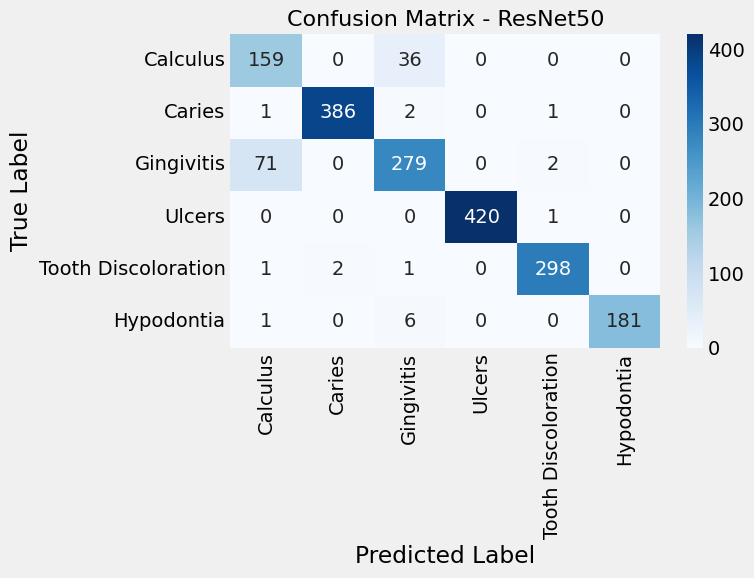

In [52]:
# Confusion matrix
cm_resnet = get_confusion_matrix(resnet_model, test_ds, "ResNet50")

In [53]:
all_results = {
    "Custom_CNN": (y_true_cnn, y_pred_cnn),
    "EfficientNetB0": (y_true_eff, y_pred_eff),
    "ResNet50": (y_true_resnet, y_pred_resnet),
}

In [55]:
CNN.save(os.path.join(OUTPUT_DIR, "custom_cnn.keras"))
efficientnet_model.save(os.path.join(OUTPUT_DIR, "efficientnetb0.keras"))
resnet_model.save(os.path.join(OUTPUT_DIR, "resnet50.keras"))

In [56]:
cnn_results = CNN.evaluate(test_ds, verbose=0, return_dict=True)
eff_results = efficientnet_model.evaluate(test_ds, verbose=0, return_dict=True)
res_results = resnet_model.evaluate(test_ds, verbose=0, return_dict=True)

comparison = pd.DataFrame({
    "Model": ["Custom_CNN", "EfficientNetB0", "ResNet50"],
    "Test Accuracy": [
        cnn_results["accuracy"],
        eff_results["accuracy"],
        res_results["accuracy"]
    ],
    "Test Loss": [
        cnn_results["loss"],
        eff_results["loss"],
        res_results["loss"]
    ]
}).sort_values("Test Accuracy", ascending=False)

print(comparison)

            Model  Test Accuracy  Test Loss
2        ResNet50       0.932359   0.166244
1  EfficientNetB0       0.906926   0.218929
0      Custom_CNN       0.888528   0.433289


In [57]:
best_model_name = comparison.iloc[0]["Model"]
models_dict = {
    "Custom_CNN": CNN,
    "EfficientNetB0": efficientnet_model,
    "ResNet50": resnet_model
}
best_model = models_dict[best_model_name]
best_model.save(os.path.join(OUTPUT_DIR, "best_model.keras"))
print(f"Best model: {best_model_name} -> saved as best_model.keras")

Best model: ResNet50 -> saved as best_model.keras


**GUI**

In [65]:
CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth Ulcer",
    "Tooth Discoloration",
]

In [ ]:
# Install Gradio
!pip install -q gradio

import os
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image


# Load the best model saved by the training notebook
MODEL_PATH = "/kaggle/working/outputs/best_model.keras"

gui_model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully")
print("Input shape:", gui_model.input_shape)
print("Output shape:", gui_model.output_shape)


# Class order must match the training notebook exactly
CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Ulcers",
    "Tooth Discoloration",
    "Hypodontia"
]


# Short information shown after prediction
CLASS_INFO = {
    "Calculus":
        "Calculus is hardened dental plaque that accumulates on the teeth and usually requires professional cleaning.",

    "Caries":
        "Dental caries refers to tooth decay caused by progressive damage to the tooth structure.",

    "Gingivitis":
        "Gingivitis is inflammation of the gums, commonly associated with plaque accumulation.",

    "Ulcers":
        "Oral ulcers are painful lesions that can develop on the soft tissues inside the mouth.",

    "Tooth Discoloration":
        "Tooth discoloration refers to changes in the normal color or appearance of the teeth.",

    "Hypodontia":
        "Hypodontia is a developmental condition in which one or more permanent teeth fail to develop."
}


IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
CONFIDENCE_THRESHOLD = 0.50


# Prepare uploaded image exactly like the training pipeline
def preprocess_image(image):

    # Make sure the image has three RGB channels
    image = image.convert("RGB")

    # Convert PIL image to float32 NumPy array
    image = np.array(image, dtype=np.float32)

    # Resize exactly like load_and_resize() in the training notebook
    image = tf.image.resize(
        image,
        (IMAGE_HEIGHT, IMAGE_WIDTH)
    )

    # Add batch dimension: (224,224,3) -> (1,224,224,3)
    image = tf.expand_dims(image, axis=0)

    # Keep pixel values in [0,255]
    # Do NOT divide by 255 here
    return image


# Make prediction
def predict_oral_disease(image):

    if image is None:
        return {}, "Please upload an oral image first."

    # Preprocess image
    batch = preprocess_image(image)

    # Predict probabilities
    probabilities = gui_model.predict(
        batch,
        verbose=0
    )[0]

    # Create probability dictionary
    predictions = {
        CLASS_NAMES[i]: float(probabilities[i])
        for i in range(len(CLASS_NAMES))
    }

    # Find most likely class
    best_index = int(np.argmax(probabilities))
    predicted_class = CLASS_NAMES[best_index]
    confidence = float(probabilities[best_index])

    # Prepare result text
    if confidence >= CONFIDENCE_THRESHOLD:

        result_text = f"""
## 🦷 Predicted Class: {predicted_class}

**Confidence: {confidence:.2%}**

{CLASS_INFO[predicted_class]}

---

⚠️ **Disclaimer:**  
This application is an educational machine-learning project and is not a medical diagnostic tool.  
Please consult a qualified dentist for professional diagnosis.
"""

    else:

        result_text = f"""
## ⚠️ Low Confidence Prediction

**Most likely class:** {predicted_class}

**Confidence: {confidence:.2%}**

The model is not sufficiently confident about this image.

Try uploading a clearer, well-lit and close-up oral image.

---

⚠️ **Disclaimer:**  
This application is an educational machine-learning project and is not a medical diagnostic tool.  
Please consult a qualified dentist for professional diagnosis.
"""

    return predictions, result_text


# Clear interface
def clear_interface():
    return None, {}, ""


# Custom appearance
CUSTOM_CSS = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

#header {
    text-align: center;
    background: linear-gradient(135deg, #102a43, #1f5fa9);
    padding: 25px;
    border-radius: 18px;
    margin-bottom: 20px;
}

#header h1 {
    color: white !important;
}

#header p {
    color: #e8f1ff !important;
}

#predict-button {
    font-size: 17px !important;
    font-weight: bold !important;
}
"""


# Build Gradio GUI
with gr.Blocks(
    title="Oral Disease Classifier",
    css=CUSTOM_CSS
) as demo:

    with gr.Column(elem_id="header"):

        gr.Markdown(
            """
# 🦷 Oral Disease Image Classifier

Upload an oral image and the trained deep-learning model will classify it into one of six categories:

**Calculus · Caries · Gingivitis · Ulcers · Tooth Discoloration · Hypodontia**
"""
        )

    with gr.Row():

        # Input side
        with gr.Column():

            image_input = gr.Image(
                type="pil",
                label="Upload Oral Image",
                sources=["upload", "webcam"],
                height=350
            )

            with gr.Row():

                predict_button = gr.Button(
                    "🔍 Classify Image",
                    variant="primary",
                    elem_id="predict-button"
                )

                clear_button = gr.Button(
                    "🗑️ Clear"
                )

        # Output side
        with gr.Column():

            probability_output = gr.Label(
                num_top_classes=6,
                label="Prediction Probabilities"
            )

            details_output = gr.Markdown()


    # Run prediction when button is clicked
    predict_button.click(
        fn=predict_oral_disease,
        inputs=image_input,
        outputs=[
            probability_output,
            details_output
        ]
    )


    # Clear everything
    clear_button.click(
        fn=clear_interface,
        inputs=None,
        outputs=[
            image_input,
            probability_output,
            details_output
        ]
    )


    gr.Markdown(
        """
---
### Model Information

- Image Size: **224 × 224**
- Number of Classes: **6**
- Framework: **TensorFlow / Keras**
- Interface: **Gradio**
"""
    )


# Launch Gradio
demo.launch(
    share=True,
    debug=True
)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
Model loaded successfully
Input shape: (None, 224, 224, 3)
Output shape: (None, 6)
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://10897d20f1a8407e5c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
